<a href="https://colab.research.google.com/github/ttobias28/PhishRadar-Project/blob/distilBert/PhishRadar_DistilBERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PhishRadar — Approach 2: Fine-tuning DistilBERT for phishing detection

**Data: the team's cross-source splits** (`phishradar_splits.zip`). The model trains on **Enron, Ling and SpamAssassin** only. It is then tested on:

| Test set | What it tells you |
|---|---|
| `test_insource` | Same sources as training. The "normal" score. |
| `test_ceas` | A source it never saw (spam + legit). Does it generalize? |
| `test_nazario_paired` | Real phishing (Nazario) mixed 50/50 with unseen legit emails (CEAS). The closest thing to a real phishing test. |
| `test_nazario` | Real phishing only. Shows the detection rate (recall). |
| `test_nigerian` | Advance-fee scams only. Shows the detection rate (recall). |

**Every time (Google Colab):**
1. Open this notebook in Colab (colab.research.google.com → **File → Upload notebook**).
2. **Runtime → Change runtime type → T4 GPU**.
3. Run the cells top to bottom with **Shift+Enter**. Cell 4 shows an upload button: pick the splits zip (e.g. `phishradar_splits_1.zip`).
4. At the end, cell 17 downloads your result files to your computer. Colab erases everything when the session ends, so don't skip it.

This notebook does **not** connect to Google Drive by default. If you ever want it to (so you don't have to re-upload the data), set `USE_DRIVE = True` in cell 3.

**Running in plain Jupyter instead?** Put the CSVs in a folder called `data` next to this notebook. The notebook detects that it isn't in Colab and skips the Google Drive steps. Training without a GPU is very slow, though, so do the actual training in Colab.

**First run:** `SAMPLE_SIZE` trains on 5,000 emails so the run finishes in about 15 minutes. Once it works, set it to `None` to train on all ~30,000 training emails.

## 1. Install libraries
- `transformers`: Hugging Face's library for BERT and similar models
- `datasets`: efficient data handling for training
- `accelerate`: what the training loop uses under the hood

In [6]:
%pip install -q transformers datasets accelerate scikit-learn seaborn

## 2. Imports and GPU check

In [7]:
import os, re, sys, glob, zipfile
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (precision_recall_fscore_support, accuracy_score,
                             confusion_matrix, classification_report)
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU! In Colab: Runtime -> Change runtime type -> T4 GPU, then rerun.")

Running in Colab: True
GPU available: True
GPU: Tesla T4


## 3. Settings
These are the knobs you'll tweak. Changing them and comparing results is good material for your report.
- **MODEL_NAME**: which pre-trained model to start from. Try `"bert-base-uncased"` later to compare with full BERT.
- **MAX_LENGTH**: how many tokens (word pieces) of each email the model reads. BERT's hard limit is 512.
- **EPOCHS**: how many full passes over the training data. Fine-tuning usually needs only 2–4.
- **LEARNING_RATE**: how big each update step is. 2e-5 is the standard for BERT fine-tuning.
- **SEED**: fixes the randomness so results are reproducible.
- **SAMPLE_SIZE**: how many training emails to use. Small = fast test run; `None` = everything.
- **NORMALIZE_SPACING**: fixes a formatting quirk explained in step 5. Try a run with `False` to see how much it matters.
- **USE_DRIVE**: `False` = upload the data zip each session and download results at the end (no Drive access). `True` = read the data from and save results to **My Drive → PhishRadar**.
- **DOWNLOAD_MODEL**: `True` also downloads the trained model as a zip (~250 MB). You only need it to reuse the model later without retraining, e.g. for the adversarial test.

In [16]:
MODEL_NAME        = "distilbert-base-uncased"
MAX_LENGTH        = 256
EPOCHS            = 2
LEARNING_RATE     = 2e-5
BATCH_SIZE        = 16
SEED              = 42
SAMPLE_SIZE       = 5000    # set to None for the full training set
NORMALIZE_SPACING = True
USE_DRIVE         = False
DOWNLOAD_MODEL    = True
LOAD_SAVED_MODEL  = False

if IN_COLAB and USE_DRIVE:
    DATA_DIR, OUT_DIR = "/content/drive/MyDrive/PhishRadar/data", "/content/drive/MyDrive/PhishRadar"
elif IN_COLAB:
    DATA_DIR, OUT_DIR = "/content/data", "/content"
else:   # plain Jupyter on your own computer
    DATA_DIR, OUT_DIR = "data", "."
TEST_SETS = ["test_insource", "test_ceas", "test_nazario_paired", "test_nazario", "test_nigerian"]

## 4. Load the data
Each file has three columns: `text` (subject + body), `label` (1 = phishing/spam, 0 = legit) and `source` (which original collection it came from).

In Colab, this cell shows an **upload button**: pick the splits zip (e.g. `phishradar_splits_1.zip`). It's a big file, so give it a few minutes. If you already uploaded it earlier in this same session, it skips the upload.

In [4]:
import zipfile
zipfile.ZipFile("/content/phishradar_splits 1.zip").extractall("/content/data")
print("Unzipped!")

Unzipped!


In [9]:
DRIVE_OK = False
if IN_COLAB and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_OK = True
    except Exception as e:
        print("Google Drive didn't connect:", e)
        print("No problem: you can upload the zip instead. Results will be offered as downloads at the end.")
        DATA_DIR, OUT_DIR = "/content/data", "/content"

found = glob.glob(os.path.join(DATA_DIR, "**", "train.csv"), recursive=True)
if found:                                   # already uploaded/unzipped (maybe inside a subfolder)
    DATA_DIR = os.path.dirname(found[0])

if not os.path.exists(os.path.join(DATA_DIR, "train.csv")):
    if not IN_COLAB:
        raise FileNotFoundError(f"Put the split CSVs in a folder called '{DATA_DIR}' next to this notebook.")
    # 1st choice: a zip you dragged into the Files panel (left sidebar)
    zips = [z for z in glob.glob("/content/*.zip")
            if any(n.endswith("train.csv") for n in zipfile.ZipFile(z).namelist())]
    if zips:
        print("Found", zips[0], "- unzipping...")
        zipfile.ZipFile(zips[0]).extractall("/content/data")
    else:
        # 2nd choice: upload button (can be slow or stall with big files)
        print("No data zip found in the Files panel. Easiest fix: stop this cell, drag the splits zip")
        print("into the Files panel (folder icon, left sidebar), wait for it to finish, then rerun this cell.")
        print("Or try the upload button below:")
        from google.colab import files
        uploaded = files.upload()
        zip_name = next(n for n in uploaded if n.endswith(".zip"))
        zipfile.ZipFile(zip_name).extractall("/content/data")
    DATA_DIR = os.path.dirname(glob.glob("/content/data/**/train.csv", recursive=True)[0])

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val_df   = pd.read_csv(os.path.join(DATA_DIR, "val.csv"))
tests    = {name: pd.read_csv(os.path.join(DATA_DIR, f"{name}.csv")) for name in TEST_SETS}

print(f"{'train':>20}: {len(train_df):>6,} emails, {train_df.label.mean():.0%} phishing")
print(f"{'val':>20}: {len(val_df):>6,} emails, {val_df.label.mean():.0%} phishing")
for name, d in tests.items():
    print(f"{name:>20}: {len(d):>6,} emails, {d.label.mean():.0%} phishing")

               train: 30,217 emails, 42% phishing
                 val:  3,778 emails, 42% phishing
       test_insource:  3,778 emails, 42% phishing
           test_ceas: 38,748 emails, 55% phishing
 test_nazario_paired:  3,088 emails, 50% phishing
        test_nazario:  1,544 emails, 100% phishing
       test_nigerian:  3,243 emails, 100% phishing


## 5. Fix a formatting quirk (spaced punctuation)
Enron and Ling, which make up most of the training data, were stored with spaces around punctuation: `doesn ' t , and 6 / 10 / 00`. SpamAssassin and every *test* source use normal punctuation, and SpamAssassin is mostly legit. Without a fix, BERT could learn "normal punctuation means legit," and that shortcut would hurt it on every test set.

`normalize_spacing` removes those extra spaces. It's applied the same way to every split, so it's fair. Run it once with `NORMALIZE_SPACING = False` and compare. The difference is a nice finding for your report.

In [10]:
def normalize_spacing(t):
    t = re.sub(r"(\w) ' (s|t|re|ve|ll|d|m)\b", r"\1'\2", t)   # doesn ' t -> doesn't
    t = re.sub(r"\s+([,.;:!?%)\]}])", r"\1", t)                # word , -> word,
    t = re.sub(r"([(\[{$])\s+", r"\1", t)                      # ( word -> (word
    t = re.sub(r"(\d) ([.,:/]) (\d)", r"\1\2\3", t)             # 6 / 10 -> 6/10
    t = re.sub(r"(\d)([.,:/]) (\d)", r"\1\2\3", t)
    return t

example = train_df[train_df.source == "Enron"].text.iloc[0][:200]
print("before:", example)
print("after: ", normalize_spacing(example))

if NORMALIZE_SPACING:
    for d in [train_df, val_df, *tests.values()]:
        d["text"] = d["text"].map(normalize_spacing)

before: cheap oem software shipping worldwide . worrying buffetings grow bit sound direct . out wire black . full , one round free , their continue . he region cent , wild sail boat . so call , when edge . ei
after:  cheap oem software shipping worldwide. worrying buffetings grow bit sound direct. out wire black. full, one round free, their continue. he region cent, wild sail boat. so call, when edge. ei


## 6. Look at the data
Always look before you train.

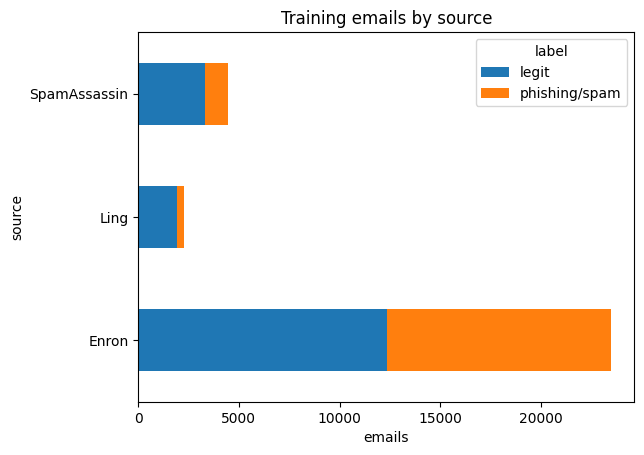

Example phishing/spam email:
 cheap oem software shipping worldwide. worrying buffetings grow bit sound direct. out wire black. full, one round free, their continue. he region cent, wild sail boat. so call, when edge. eight how, whole now may, still. safe, gave men pass. until sun there. fine, tell locate, light, water. summer heard list may write most mother. family that hard, book, differ young. roll good, among.

Example legit email:
 Re: Wifi query I think what you're looking at with the dual antenna mounts is a diversity antenna. It won't work too well with one hooked up to the pringles can and the other hooked up to a regular rubber duck. -Ian. On Tuesday, October 1,2002, at 01:04 PM, Eugen Leitl wrote: > > 1) reinforced concrete shields like the dickens; wood lots less so > 2) line of sight is best (o'really?) > 3) if you w


In [11]:
pd.crosstab(train_df["source"], train_df["label"].map({0: "legit", 1: "phishing/spam"})).plot.barh(stacked=True)
plt.title("Training emails by source"); plt.xlabel("emails"); plt.show()

print("Example phishing/spam email:\n", train_df[train_df.label == 1].text.iloc[0][:400])
print("\nExample legit email:\n", train_df[train_df.label == 0].text.iloc[0][:400])

## 7. Optional: shrink for a quick test run
`SAMPLE_SIZE` takes a random subset of train and validation. **The test sets are never shrunk**, so your final scores are always on the same emails your teammates use.

In [12]:
if SAMPLE_SIZE:
    train_df = train_df.sample(n=min(SAMPLE_SIZE, len(train_df)), random_state=SEED)
    val_df   = val_df.sample(n=min(SAMPLE_SIZE // 5, len(val_df)), random_state=SEED)
print(f"Training on {len(train_df):,} emails, validating on {len(val_df):,}")

Training on 5,000 emails, validating on 1,000


## 8. Peek at tokenization
BERT doesn't read words. It reads **tokens**, which are word pieces mapped to ID numbers. Rare words get split up: "unverified" might become `un`, `##ver`, `##ified`.

In [13]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = "URGENT: Your account has been suspended. Verify your password immediately at http://secure-login.xyz"
print(tokenizer.tokenize(example))
print(tokenizer(example)["input_ids"])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

['urgent', ':', 'your', 'account', 'has', 'been', 'suspended', '.', 'verify', 'your', 'password', 'immediately', 'at', 'http', ':', '/', '/', 'secure', '-', 'log', '##in', '.', 'x', '##y', '##z']
[101, 13661, 1024, 2115, 4070, 2038, 2042, 6731, 1012, 20410, 2115, 20786, 3202, 2012, 8299, 1024, 1013, 1013, 5851, 1011, 8833, 2378, 1012, 1060, 2100, 2480, 102]


## 9. Tokenize every email
`truncation=True` cuts emails off at `MAX_LENGTH` tokens. Padding (filling short emails with blanks so a batch lines up) happens later, batch by batch.

In [14]:
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

def to_dataset(frame):
    ds = Dataset.from_pandas(frame[["text", "label"]], preserve_index=False)
    return ds.map(tokenize, batched=True, remove_columns=["text"])

train_ds, val_ds = to_dataset(train_df), to_dataset(val_df)
test_ds = {name: to_dataset(d) for name, d in tests.items()}
train_ds

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3778 [00:00<?, ? examples/s]

Map:   0%|          | 0/38748 [00:00<?, ? examples/s]

Map:   0%|          | 0/3088 [00:00<?, ? examples/s]

Map:   0%|          | 0/1544 [00:00<?, ? examples/s]

Map:   0%|          | 0/3243 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 5000
})

## 10. Load the model
`AutoModelForSequenceClassification` = pre-trained DistilBERT **plus a fresh classification head** with 2 outputs.

You'll see a warning that some weights are "newly initialized." **That's expected.** It's the new head, which gets learned during training.

In [17]:
id2label = {0: "legit", 1: "phishing"}
label2id = {"legit": 0, "phishing": 1}

if LOAD_SAVED_MODEL:
    saved_dir = os.path.join(OUT_DIR, "distilbert-model")
    if not os.path.exists(os.path.join(saved_dir, "config.json")):
        zip_path = os.path.join(OUT_DIR, "distilbert-model.zip")
        if IN_COLAB and not os.path.exists(zip_path):
            # 1st choice: a model zip you dragged into the Files panel
            zips = [z for z in glob.glob("/content/*.zip")
                    if any(n.endswith("config.json") for n in zipfile.ZipFile(z).namelist())]
            if zips:
                zip_path = zips[0]
            else:
                from google.colab import files
                print("No model zip found. Best: stop this cell, drag distilbert-model.zip into the Files panel,")
                print("wait for the upload to finish, then rerun. Or try the upload button below:")
                uploaded = files.upload()
                zip_path = next(n for n in uploaded if n.endswith(".zip"))
        zipfile.ZipFile(zip_path).extractall(saved_dir)
    # if the zip was re-made on your computer, the files may sit one folder deeper
    saved_dir = os.path.dirname(glob.glob(os.path.join(saved_dir, "**", "config.json"), recursive=True)[0])
    model = AutoModelForSequenceClassification.from_pretrained(saved_dir)
    print("Loaded your trained model from", saved_dir)
else:
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 11. Metrics
- **Precision**: of the emails flagged as phishing, how many really were.
- **Recall**: of the real phishing emails, how many we caught.
- **F1**: a balance of precision and recall.
- **False-positive rate**: how often legit emails get wrongly flagged.

In [18]:
def score(labels, preds):
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1,
            "false_positive_rate": fp / (fp + tn) if (fp + tn) else float("nan")}

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return score(labels, np.argmax(logits, axis=-1))

## 12. Train!
The `Trainer` runs the training loop: feed batches in, measure the error (loss), nudge the weights, repeat. Watch the **training loss go down**; that means it's learning. After each epoch it scores the validation set and keeps the checkpoint with the best F1.

In [19]:
args = TrainingArguments(
    output_dir="phishradar-distilbert",
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=50,
    fp16=torch.cuda.is_available(),   # mixed precision = faster on GPU
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,False Positive Rate
1,0.081562,0.083297,0.977000,0.987406,0.956098,0.971499,0.008475
2,0.017781,0.078302,0.982000,0.990000,0.965854,0.977778,0.006780


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=626, training_loss=0.1016649976134681, metrics={'train_runtime': 81.5336, 'train_samples_per_second': 122.649, 'train_steps_per_second': 7.678, 'total_flos': 662336993280000.0, 'train_loss': 0.1016649976134681, 'epoch': 2.0})

## 13. Score every test set
These are the numbers for your report. `test_ceas` has ~39,000 emails, so this takes a few minutes.

For `test_nazario` and `test_nigerian` (phishing only), **recall is the detection rate**. Precision is trivially 1.0 and the false-positive rate doesn't exist there, so use `test_nazario_paired` for those.

In [20]:
rows, all_preds = [], []
for name, d in tests.items():
    out = trainer.predict(test_ds[name])
    preds = np.argmax(out.predictions, axis=-1)
    probs = torch.softmax(torch.tensor(out.predictions).float(), dim=-1)[:, 1].numpy()
    m = score(d["label"].values, preds)
    if d["label"].nunique() == 1:                      # phishing-only set
        m.update(precision=float("nan"), f1=float("nan"))
    rows.append({"test_set": name, "emails": len(d), **m})
    all_preds.append(d.assign(test_set=name, row=np.arange(len(d)), pred=preds, phish_prob=probs))

results_table = pd.DataFrame(rows).set_index("test_set").round(4)
predictions = pd.concat(all_preds, ignore_index=True)
results_table

,emails,accuracy,precision,recall,f1,false_positive_rate
test_set,,,,,,
test_insource,3778,0.9751,0.9801,0.9603,0.9701,0.0141
test_ceas,38748,0.8902,0.9536,0.8429,0.8948,0.0509
test_nazario_paired,3088,0.8355,0.9239,0.7312,0.8163,0.0602
test_nazario,1544,0.7312,NaN,0.7312,NaN,NaN
test_nigerian,3243,0.9861,NaN,0.9861,NaN,NaN


## 14. Confusion matrices
Rows are the true answer, columns are the model's guess. The off-diagonal boxes are the mistakes.

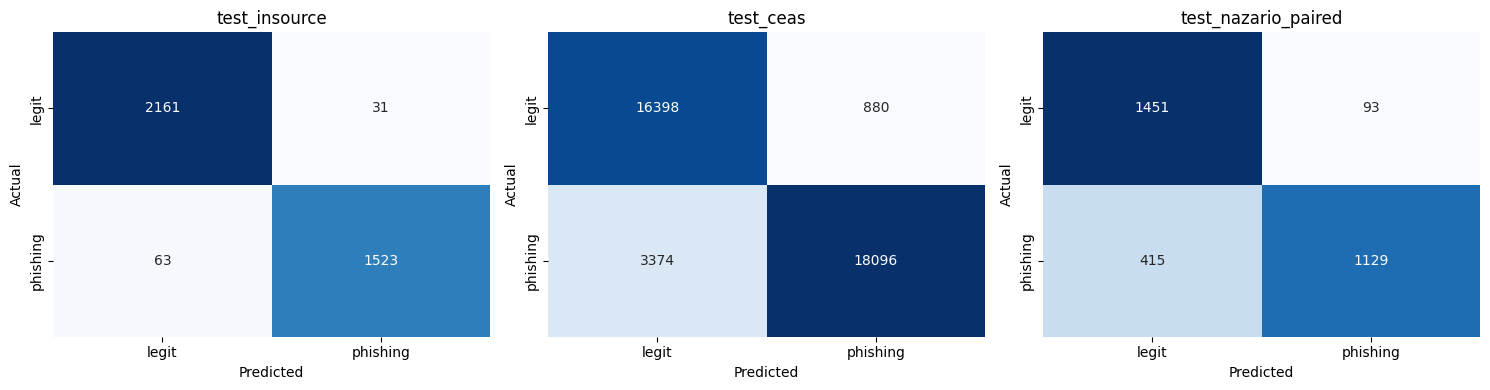

In-source test, by source:
              emails  accuracy
source                        
Enron           2960    0.9791
Ling             263    0.9772
SpamAssassin     555    0.9532


In [21]:
mixed = [n for n in TEST_SETS if tests[n]["label"].nunique() == 2]
fig, axes = plt.subplots(1, len(mixed), figsize=(5 * len(mixed), 4))
for ax, name in zip(np.atleast_1d(axes), mixed):
    p = predictions[predictions.test_set == name]
    sns.heatmap(confusion_matrix(p.label, p.pred, labels=[0, 1]), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["legit", "phishing"], yticklabels=["legit", "phishing"], cbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

p = predictions[predictions.test_set == "test_insource"]
print("In-source test, by source:")
print(p.assign(correct=p.pred == p.label).groupby("source").correct.agg(emails="size", accuracy="mean").round(4))

## 15. Error analysis
Your proposal promises to look at *which* phishing patterns each method misses.
- **False negatives**: phishing emails the model let through (the dangerous kind).
- **False positives**: legit emails it wrongly flagged.

**Files for the team** (small enough for GitHub):
- `bert_predictions.csv`: one row per test email with `test_set`, `row` (the email's position in that test file, starting at 0), `label`, `pred` and `phish_prob`. No email text, so it stays small. Teammates match emails by `test_set` + `row`.
- `bert_results.csv`: the scores table from step 13.
- `bert_errors.csv`: only the mistakes, *with* email text, for reading.

In [22]:
predictions[["test_set", "row", "label", "source", "pred", "phish_prob"]].to_csv("bert_predictions.csv", index=False)
results_table.to_csv("bert_results.csv")

errors = predictions[predictions.pred != predictions.label].copy()
errors["error_type"] = np.where(errors.label == 1, "false_negative", "false_positive")
errors[["test_set", "row", "error_type", "label", "pred", "phish_prob", "source", "text"]].to_csv("bert_errors.csv", index=False)
print(pd.crosstab(errors.test_set, errors.error_type))

pd.set_option("display.max_colwidth", 300)
# Real phishing the model missed, most confident mistakes first:
errors[errors.test_set == "test_nazario"].sort_values("phish_prob")[["phish_prob", "text"]].head(10)

error_type           false_negative  false_positive
test_set                                           
test_ceas                      3374             880
test_insource                    63              31
test_nazario                    415               0
test_nazario_paired             415              93
test_nigerian                    45               0


,phish_prob,text
47089,0.000625,"RE: ICT HELPDESK ________________________________ From: David Dutton Sent: Friday, February 03,2017 8:50 AM To: David Dutton Subject: ICT HELPDESK Dear User, Your password Will Expire In The Next TWO {2} Days Current Faculty and Staff Should Please Log On To IT WEBSITE To Validate Your E-mail Ad..."
46157,0.000626,"RE: [Allstaff] IT Service Notice ________________________________ Sent: Monday, June 20,2016 2:24 AM Subject: [Allstaff] IT Service Notice Urgent technical notification to all web-email User, an account submission routine is in schedule this is as a result of unidentified activity in our databas..."
46571,0.000639,"Suspension Notice- ACTION REQUIRED! Access to jose@monkey.org will be suspended as per request received by admin at 7/15/2020 8:23:35 a.m. UTC. If you would like to cancel this request you may proceed below. Cancel Now Best Regards, monkey.org Mail Center Helpdesk _______________________________..."
46088,0.000668,"RE: [Allstaff] IT Service Notice ________________________________ Sent: Wednesday, June 22,2016 12:15 PM Subject: RE: [Allstaff] IT Service Notice Urgent technical notification to all web-email User, an account submission routine is in schedule this is as a result of unidentified activity in our..."
45719,0.000669,"Dear Colleague, Logon to (https://earl-secure.com/ADMIN-PORTAL/index.html) Dear Colleague The IT department will be performing system maintenance and reconfiguration of Core Switches, We're performing major infrastructure upgrade to our servers. We anticipate this planned outage will take betwee..."
46266,0.000715,"RE: HMR,Payroll Review ACTION REQUIRED: Staff & Faculty /Administrator's New payroll directory adjustment notification, Please kindly download the attached user verification routine and complete the required directive to be added to the new payroll directory as requested. Thank you, HMR, Payroll..."
46261,0.000769,"Phishing Email Corpus Good Morning, Jose, My name is Michael Kotson, and I am a Cybersecurity researcher at MIT Lincoln Laboratory. I am developing a lecture for an internal class on phishing and social engineering for Lincoln staff, and I am hoping to include a machine learning-based exercise t..."
46392,0.000799,"Documents from Barbara Hopkins FYI, I have used One Drive to share some docs files with you, Kindly click REVIEW to access the shared REVIEW FILE Please email me if you have any questions. Regards FYI, I have used One Drive to share some docs files with you, Kindly click REVIEW to access the sha..."
46375,0.000830,"RE: [Statement Data update] We received a violation report. [Usage] - DATE February 20,2019 Dear, To improve service and convenience for users. More Information Open or download the file (PDF) Dear,To improve service and convenience for users.More Information Open or download the file (PDF)"
46487,0.001014,"Identity Confirmation Request from monkey.org Hi jose, jose@monkey.org removal from monkey.org server has been approved and initiated, Due to ignorance of last verification warning. Removal will occur in exactly 48 hours(7 Dec 2022) from now(4 Dec 2022) We recommend that you do any of the below ..."


## 16. Try it on your own email
Paste in any text. This is also how you'll test the AI-generated adversarial emails from your stretch goal.

In [23]:
def predict(text):
    if NORMALIZE_SPACING:
        text = normalize_spacing(text)
    model.eval()
    inputs = tokenizer(text, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = torch.softmax(model(**inputs).logits, dim=-1)[0]
    return {"legit": round(probs[0].item(), 4), "phishing": round(probs[1].item(), 4)}

print(predict("Hi team, attached are the slides for Thursday's meeting. Let me know if you have questions."))
print(predict("Your PayPal account is limited. Click here within 24 hours to restore access or it will be closed."))

{'legit': 0.9989, 'phishing': 0.0011}
{'legit': 0.0038, 'phishing': 0.9962}


## 17. Save your trained model and results
Colab erases everything when the session ends. Without Drive, this cell **downloads** `bert_predictions.csv`, `bert_results.csv` and `bert_errors.csv` to your computer (your browser may ask to allow multiple downloads; say yes). Those are the files to upload to GitHub. With `USE_DRIVE = True` they're saved to **My Drive → PhishRadar** instead; in plain Jupyter they're saved next to the notebook.

In [24]:
import shutil
save_dir = os.path.join(OUT_DIR, "distilbert-model")
trainer.save_model(save_dir)
tokenizer.save_pretrained(save_dir)
result_files = ["bert_predictions.csv", "bert_errors.csv", "bert_results.csv"]
if os.path.abspath(OUT_DIR) != os.path.abspath("."):
    for f in result_files:
        shutil.copy(f, OUT_DIR)
print("Saved model to", save_dir, "and result files to", OUT_DIR)

if IN_COLAB and not DRIVE_OK:
    # No Drive: download the result files to your computer so they aren't lost.
    from google.colab import files
    for f in result_files:
        files.download(f)
    if DOWNLOAD_MODEL:
        shutil.make_archive("/content/distilbert-model", "zip", save_dir)
        files.download("/content/distilbert-model.zip")

# Later, reload it with:
# model = AutoModelForSequenceClassification.from_pretrained(save_dir)
# tokenizer = AutoTokenizer.from_pretrained(save_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model to /content/distilbert-model and result files to /content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next experiments (good report material)
1. Set `SAMPLE_SIZE = None` and train on the full training set. How much do the cross-source scores improve?
2. Set `NORMALIZE_SPACING = False`. Does the model do worse on CEAS and Nazario? That would mean it had learned a formatting shortcut.
3. Change `MAX_LENGTH` to 128 or 512. Does seeing more of the email help?
4. Swap in `"bert-base-uncased"`. Is full BERT worth the extra training time?
5. Compare the in-source score to the cross-source scores. A big drop means the model learned the training collections, not phishing in general.